In [ ]:
# 0.1 Install dependencies (run once in Google Colab if needed)
%pip install -q yfinance pandas numpy matplotlib seaborn scipy scikit-learn openpyxl

In [ ]:
# 0.2 Import libraries and record package versions
import os
import sys
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

PACKAGE_VERSIONS = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}

print("Package versions:")
for package, version in PACKAGE_VERSIONS.items():
    print(f"{package}: {version}")

Package versions:
Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
yfinance: 0.2.66
scipy: 1.16.3
scikit-learn: 1.6.1


In [ ]:
import os
import pandas as pd

# 1.1 Study settings
START_DATE = "2021-01-01"
END_DATE = "2025-01-01"       # exclusive
BENCHMARK_TICKER = "^GSPC"

# Adapted RFM settings required by the coursework
BASELINE_SESSIONS = 20
RFM_WINDOW_SESSIONS = 60
HIGH_VOLUME_MULTIPLIER = 2.0

# Beta reliability check
MIN_PAIRED_WEEKS = 52

# Clustering settings
RANDOM_STATE = 42
K_VALUES = range(2, 9)        # compare k = 2 to 8
KMEANS_N_INIT = 20

OUTPUT_DIR = "coursework_outputs_20232098"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Record the date on which the constituent list is retrieved
TICKER_RETRIEVAL_DATE = pd.Timestamp.now(tz="UTC").date().isoformat()

print("Study period:", START_DATE, "to", END_DATE, "(end date exclusive)")
print("Ticker-list retrieval date (UTC):", TICKER_RETRIEVAL_DATE)
print("Output folder:", OUTPUT_DIR)

Study period: 2021-01-01 to 2025-01-01 (end date exclusive)
Ticker-list retrieval date (UTC): 2026-11-25
Output folder: coursework_outputs_20232098


In [ ]:
# 2.1 Extract and save the current S&P 500 constituent list
constituents_url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

tables = pd.read_html(
    constituents_url,
    storage_options={"User-Agent": "Mozilla/5.0 (compatible; coursework research)"}
)
constituents = tables[0].copy()

required_columns = {"Symbol", "Security", "GICS Sector"}
missing_columns = required_columns.difference(constituents.columns)
if missing_columns:
    raise ValueError(f"Constituents table is missing columns: {missing_columns}")

constituents = constituents[["Symbol", "Security", "GICS Sector"]].copy()
constituents["Yahoo_Ticker"] = constituents["Symbol"].str.replace(".", "-", regex=False)
constituents = constituents.drop_duplicates(subset="Yahoo_Ticker").reset_index(drop=True)

ticker_metadata = constituents.rename(columns={
    "Symbol": "Wikipedia_Symbol",
    "Security": "Company",
    "GICS Sector": "Sector"
})

tickers = ticker_metadata["Yahoo_Ticker"].tolist()

ticker_metadata.to_csv(os.path.join(OUTPUT_DIR, "sp500_ticker_list.csv"), index=False)

print("Number of tickers retrieved:", len(tickers))
print("Ticker-list retrieval date:", TICKER_RETRIEVAL_DATE)
display(ticker_metadata.head())

Number of tickers retrieved: 503
Ticker-list retrieval date: 2026-11-25


,Wikipedia_Symbol,Company,Sector,Yahoo_Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN


In [ ]:
# 2.2 Download share and benchmark data
download_tickers = tickers + [BENCHMARK_TICKER]

raw_data = yf.download(
    tickers=download_tickers,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=False,
    actions=True,
    group_by="column",
    threads=True,
    progress=True
)

if raw_data.empty:
    raise RuntimeError(
        "Yahoo Finance returned no data. Check internet access and rerun. "
        "If access remains unavailable, use a documented cached dataset for the exact study period."
    )

print("Downloaded data shape:", raw_data.shape)
print("Downloaded fields:", list(raw_data.columns.get_level_values(0).unique())
      if isinstance(raw_data.columns, pd.MultiIndex) else list(raw_data.columns))
display(raw_data.head())

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'FDXF', 'SNDK', 'HONA', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloaded data shape: (1005, 4022)
Downloaded fields: ['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']


Price        Adj Close                                                                                                                                  \
Ticker               A        AAPL       ABBV        ABNB        ABT       ACGL         ACN        ADBE         ADI        ADM         ADP        ADSK   
Date                                                                                                                                                     
2021-01-04  114.009125  125.537125  84.219131  139.149994  97.269684  33.186359  232.029358  485.339996  132.622620  42.189487  148.964676  296.839996   
2021-01-05  114.941269  127.089226  85.090012  148.300003  98.473206  33.319485  233.350281  485.690002  134.993164  43.010090  148.550308  301.700012   
2021-01-06  118.093224  122.811195  84.354965  142.770004  98.268173  34.783871  235.901642  466.309998  135.601669  44.752827  148.030121  302.869995   
2021-01-07  121.235603  127.001915  85.257805  151.270004  99.222046  34.460564  238.127365  477.739990  141.332748  44.355221  148.867691  315.200012   
2021-01-08  122.100479  128.098083  85.705215  149.770004  99.498398  34.650742  238.995834  485.100006  142.359055  44.473656  150.807327  319.850006   

Price                                                                                                                                                 \
Ticker            AEE        AEP        AES        AFL        AIG         AIZ         AJG        AKAM         ALB        ALGN        ALL        ALLE   
Date                                                                                                                                                   
2021-01-04  64.388977  65.872742  18.430201  37.676273  32.501888  119.872223  112.987907  105.239998  142.653687  526.460022  94.200172  106.037796   
2021-01-05  64.076050  65.783875  19.048773  37.737347  33.044601  119.908478  112.236130  105.419998  152.280472  543.650024  93.459335  106.241585   
2021-01-06  64.608879  66.308998  19.810091  39.194153  35.197968  125.171219  114.575958  101.529999  163.655029  540.390015  95.864876  108.659103   
2021-01-07  62.790470  64.539764  19.611830  38.976074  35.793213  126.432526  114.951836  102.809998  171.973236  558.359985  95.934593  111.521233   
2021-01-08  63.433262  63.966194  20.159029  38.810326  35.556870  125.770111  113.561081  103.459999  172.066788  570.530029  95.830017  111.132210   

Price                                                                                                                                                 \
Ticker           AMAT       AMCR        AMD         AME        AMGN         AMP         AMT        AMZN       ANET         AON        AOS        APA   
Date                                                                                                                                                   
2021-01-04  82.770493  43.004158  92.300003  114.068634  188.669922  171.959778  183.980759  159.331497  17.697500  195.593506  48.167683  12.576364   
2021-01-05  85.371658  43.306477  92.769997  114.858765  189.585526  170.954239  184.910706  160.925507  17.875626  195.354462  48.480339  13.776951   
2021-01-06  86.543617  44.515732  90.330002  119.724846  194.155380  180.762955  180.034714  156.919006  17.866875  197.725845  50.150841  14.338929   
2021-01-07  90.097580  44.137844  95.160004  119.869408  194.796326  182.947754  182.221390  158.108002  18.498125  197.515503  50.767223  14.568828   
2021-01-08  91.050392  43.457642  94.580002  119.040703  198.517090  184.245865  186.159042  159.134995  19.132500  196.234177  50.168705  14.117544   

Price                                                                                                                                                      \
Ticker             APD        APH        APO APP        APTV         ARE       ARES        ATO       AVGO         AVY         AWK        AXON         AXP   
Date               

In [ ]:
# 3.1 Helper function to extract a field from yfinance's column format
def extract_field(download_frame, field_name):
    if isinstance(download_frame.columns, pd.MultiIndex):
        if field_name not in download_frame.columns.get_level_values(0):
            return None
        field = download_frame[field_name].copy()
    else:
        if field_name not in download_frame.columns:
            return None
        field = download_frame[[field_name]].copy()
        field.columns = [BENCHMARK_TICKER]
    return field.sort_index()


adj_close_all = extract_field(raw_data, "Adj Close")
close_all = extract_field(raw_data, "Close")
volume_all = extract_field(raw_data, "Volume")
dividends_all = extract_field(raw_data, "Dividends")
splits_all = extract_field(raw_data, "Stock Splits")

if close_all is None or volume_all is None:
    raise RuntimeError("Close and Volume fields are required but were not returned.")

# Prefer adjusted prices for weekly returns and beta.
# If Yahoo Finance does not return Adj Close at all, use Close consistently and record this limitation.
if adj_close_all is None:
    print("WARNING: Adj Close was unavailable. Close will be used consistently for weekly returns and beta.")
    weekly_price_field = "Close"
    weekly_prices_all = close_all.copy()
else:
    weekly_price_field = "Adj Close"
    weekly_prices_all = adj_close_all.copy()

print("Price field used for weekly returns and beta:", weekly_price_field)

Price field used for weekly returns and beta: Adj Close


In [ ]:
# 3.2 Normalise date indexes and remove duplicate dates transparently
def clean_date_index(frame, frame_name):
    if frame is None:
        return None
    result = frame.copy()
    result.index = pd.to_datetime(result.index)
    if getattr(result.index, "tz", None) is not None:
        result.index = result.index.tz_localize(None)
    duplicate_count = int(result.index.duplicated().sum())
    if duplicate_count:
        print(f"{frame_name}: removing {duplicate_count} duplicate date rows (keeping last).")
        result = result[~result.index.duplicated(keep="last")]
    return result.sort_index()

weekly_prices_all = clean_date_index(weekly_prices_all, "Weekly price source")
close_all = clean_date_index(close_all, "Close")
volume_all = clean_date_index(volume_all, "Volume")
if dividends_all is not None:
    dividends_all = clean_date_index(dividends_all, "Dividends")
if splits_all is not None:
    splits_all = clean_date_index(splits_all, "Stock Splits")

# Keep dates inside the requested half-open interval.
start_ts = pd.Timestamp(START_DATE)
end_ts = pd.Timestamp(END_DATE)

def restrict_period(frame):
    if frame is None:
        return None
    return frame.loc[(frame.index >= start_ts) & (frame.index < end_ts)]

weekly_prices_all = restrict_period(weekly_prices_all)
close_all = restrict_period(close_all)
volume_all = restrict_period(volume_all)
dividends_all = restrict_period(dividends_all)
splits_all = restrict_period(splits_all)

print("Date range returned:", weekly_prices_all.index.min(), "to", weekly_prices_all.index.max())

Date range returned: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


In [ ]:
# 3.3 Build an explicit share validation and exclusion log
validation_rows = []
valid_tickers = []

for ticker in tickers:
    reasons = []

    if ticker not in close_all.columns or ticker not in volume_all.columns or ticker not in weekly_prices_all.columns:
        validation_rows.append({"Ticker": ticker, "Included": False, "Reason": "Required price or volume field unavailable"})
        continue

    close_series = close_all[ticker]
    volume_series = volume_all[ticker]
    weekly_price_series = weekly_prices_all[ticker]

    if close_series.dropna().empty or weekly_price_series.dropna().empty:
        reasons.append("No usable price history")

    if (close_series.dropna() <= 0).any():
        reasons.append("Non-positive Close price detected")

    if (weekly_price_series.dropna() <= 0).any():
        reasons.append(f"Non-positive {weekly_price_field} detected")

    if (volume_series.dropna() < 0).any():
        reasons.append("Negative volume detected")

    # A share must have enough valid daily observations for the 20-session baseline + 60-session RFM window.
    paired_daily = pd.concat([close_series, volume_series], axis=1).dropna()
    if len(paired_daily) < (BASELINE_SESSIONS + RFM_WINDOW_SESSIONS):
        reasons.append("Insufficient paired daily Close/Volume history for RFM window")

    included = len(reasons) == 0
    if included:
        valid_tickers.append(ticker)

    validation_rows.append({
        "Ticker": ticker,
        "Included": included,
        "Valid_Close_Volume_Sessions": len(paired_daily),
        "Missing_Close": int(close_series.isna().sum()),
        "Missing_Volume": int(volume_series.isna().sum()),
        "Reason": "; ".join(reasons) if reasons else "Passed initial validation"
    })

validation_log = pd.DataFrame(validation_rows)
validation_log.to_csv(os.path.join(OUTPUT_DIR, "share_validation_log.csv"), index=False)

print("Tickers downloaded:", len(tickers))
print("Tickers passed initial validation:", len(valid_tickers))
print("Tickers excluded:", len(tickers) - len(valid_tickers))
display(validation_log["Reason"].value_counts().rename_axis("Reason").to_frame("Shares"))
display(validation_log.head(10))

Tickers downloaded: 503
Tickers passed initial validation: 498
Tickers excluded: 5


,Shares
Reason,
Passed initial validation,498
No usable price history; Insufficient paired daily Close/Volume history for RFM window,5


,Ticker,Included,Valid_Close_Volume_Sessions,Missing_Close,Missing_Volume,Reason
0,MMM,True,1005,0,0,Passed initial validation
1,AOS,True,1005,0,0,Passed initial validation
2,ABT,True,1005,0,0,Passed initial validation
3,ABBV,True,1005,0,0,Passed initial validation
4,ACN,True,1005,0,0,Passed initial validation
5,ADBE,True,1005,0,0,Passed initial validation
6,AMD,True,1005,0,0,Passed initial validation
7,AES,True,1005,0,0,Passed initial validation
8,AFL,True,1005,0,0,Passed initial validation
9,A,True,1005,0,0,Passed initial validation


In [ ]:
# 3.4 Check benchmark availability and create aligned share price matrices
if BENCHMARK_TICKER not in weekly_prices_all.columns:
    raise RuntimeError("S&P 500 benchmark ^GSPC is missing from the download.")

benchmark_prices = weekly_prices_all[BENCHMARK_TICKER].dropna()
if benchmark_prices.empty or (benchmark_prices <= 0).any():
    raise RuntimeError("Benchmark price series is empty or contains non-positive prices.")

share_weekly_prices = weekly_prices_all[valid_tickers].copy()
share_close_prices = close_all[valid_tickers].copy()
share_volumes = volume_all[valid_tickers].copy()

# Save a compact data snapshot for reproducibility.
share_weekly_prices.to_csv(os.path.join(OUTPUT_DIR, "share_weekly_price_snapshot.csv"))
benchmark_prices.to_frame("Benchmark_Price").to_csv(
    os.path.join(OUTPUT_DIR, "benchmark_price_snapshot.csv")
)

print("Share price matrix:", share_weekly_prices.shape)
print("Benchmark observations:", len(benchmark_prices))

Share price matrix: (1005, 498)
Benchmark observations: 1005


In [ ]:
# 4.1 Resample daily prices to Friday-ending weeks
def to_friday_weekly_prices(price_frame):
    weekly = price_frame.resample("W-FRI").last()
    # A weekly label is a Friday. Keep only bins whose Friday-ending week is inside the study window.
    week_starts = weekly.index - pd.Timedelta(days=4)
    complete_week_mask = (week_starts >= start_ts) & (weekly.index < end_ts)
    return weekly.loc[complete_week_mask]

share_weekly = to_friday_weekly_prices(share_weekly_prices)
market_weekly = to_friday_weekly_prices(benchmark_prices.to_frame(BENCHMARK_TICKER))

share_weekly_returns = share_weekly.pct_change(fill_method=None)
market_weekly_returns = market_weekly[BENCHMARK_TICKER].pct_change(fill_method=None)

# Align all share and benchmark weekly returns on identical week labels.
common_week_labels = share_weekly_returns.index.intersection(market_weekly_returns.index)
share_weekly_returns = share_weekly_returns.loc[common_week_labels]
market_weekly_returns = market_weekly_returns.loc[common_week_labels]

print("Weekly return matrix:", share_weekly_returns.shape)
print("Benchmark weekly return observations:", market_weekly_returns.notna().sum())
display(share_weekly_returns.head())

Weekly return matrix: (208, 498)
Benchmark weekly return observations: 207


Ticker,MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,ABNB,AKAM,ALB,ARE,ALGN,ALLE,LNT,ALL,GOOGL,GOOG,MO,AMZN,AMCR,AEE,AEP,AXP,AIG,AMT,AWK,AMP,AME,AMGN,APH,ADI,AON,APA,APO,AAPL,AMAT,APP,APTV,ACGL,ADM,ARES,ANET,AJG,AIZ,T,ATO,...,TSN,USB,UBER,UDR,ULTA,UNP,UAL,UPS,URI,UNH,UHS,VLO,VEEV,VTR,VLTO,VRSN,VRSK,VZ,VRTX,VRT,VTRS,VICI,V,VST,VMRK,VMC,WRB,GWW,WAB,WMT,DIS,WM,WAT,WEC,WFC,WELL,WST,WDC,WY,WSM,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006422,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,0.004095,0.130200,0.028900,-0.021510,0.014827,-0.005784,-0.046424,0.002432,-0.014097,-0.039053,-0.039298,-0.009377,-0.024649,-0.039131,-0.008133,0.016292,0.003038,0.017971,-0.010396,0.017454,0.033391,-0.036749,0.029351,-0.026743,0.006444,0.013205,0.041616,0.021082,-0.037183,0.079322,NaN,-0.019305,-0.048024,-0.007038,-0.049884,0.035770,-0.039222,0.011254,0.005169,0.008626,...,0.011245,-0.018654,0.042042,0.054574,0.025794,-0.010146,0.013860,0.003220,-0.019258,-0.033270,-0.061358,0.010223,-0.060754,0.039033,NaN,-0.035418,-0.054156,-0.007266,-0.048312,0.079690,-0.068306,-0.019868,-0.064330,0.024774,0.057158,-0.011730,-0.003315,-0.020218,0.008248,-0.013571,-0.040573,-0.032715,0.024864,0.008414,-0.034649,0.025048,-0.026404,-0.011772,-0.025764,0.157290,0.056338,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038963
2021-01-22,0.021081,0.016365,0.013836,0.003076,0.004415,0.031348,0.051922,-0.018116,-0.001076,0.000951,-0.011537,0.074437,0.024519,-0.035694,0.002792,-0.058442,-0.006993,-0.001213,0.018727,0.095473,0.094955,0.015291,0.060556,0.003620,-0.020298,0.020007,0.032665,-0.030714,0.018327,0.007451,0.016852,-0.013866,0.032629,0.003795,-0.013756,-0.007070,-0.050175,-0.031700,0.093833,0.030929,NaN,-0.022837,-0.039781,0.011877,0.003102,-0.018482,0.014900,-0.037597,-0.008228,-0.010441,...,0.027336,-0.052479,-0.021794,-0.007864,-0.006394,-0.043721,-0.039872,0.000566,0.013522,-0.010675,-0.025513,0.019726,0.065237,0.003063,NaN,-0.002663,0.014419,0.001568,0.053381,0.025628,0.022288,0.048887,0.002133,-0.007904,-0.000487,-0.015847,-0.003931,0.012427,-0.017460,0.011684,0.007816,0.005579,0.019715,-0.014771,-0.004369,-0.018366,0.002841,-0.009764,0.021218,0.064135,-0.040000,-0.000726,0.058276,0.011485,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012523
2021-01-29,0.039162,-0.055285,0.095268,-0.075591,-0.050437,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,-0.059379,0.009677,0.018063,-0.063611,-0.010246,-0.016290,-0.058093,-0.007213,-0.029430,-0.034451,-0.034354,-0.017930,-0.026131,-0.013526,-0.002195,-0.014254,-0.078326,-0.065868,0.015363,-0.011746,-0.065725,-0.034853,-0.047614,-0.055656,-0.053027,-0.014079,-0.128205,-0.010553,-0.051125,-0.090755,NaN,-0.042225,-0.057040,-0.053200,-0.002650,-0.011728,-0.020621,0.004225,-0.010370,-0.001010,...,-0.033223,-0.065635,-0.062235,-0.016876,-0.067218,-0.046638,-0.051020,-0.025096,-0.060250,-0.040196,-0.034237,-0.050799,-0.042433,-0.062284,NaN,-0.003492,-0.048039,-0.047329,-0.035818,0.005497,-0.025244,-0.042062,-0.043412,-0.064199,0.001299,-0.058281,-0.056770,-0.073954,-0.077793,-0.039910,-0.026681,-0.035021,-0.032710,0.017395,-0.063323,-0.039163,-0.001999,0.112798,-0.060825,-0.025695,-0.017129,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052293,-0.051389,-0.045587,-0.055593
2021-02-05,0.019071,0.104973,0.003560,0.060988,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,-0.051020,0.063606,0.032784,-0.033752,0.027467

In [ ]:

# 4.2 Calculate mean weekly return and weekly beta for each share
risk_return_rows = []

for ticker in share_weekly_returns.columns:
    paired = pd.concat(
        [
            share_weekly_returns[ticker].rename("Share_Return"),
            market_weekly_returns.rename("Market_Return")
        ],
        axis=1
    ).replace([np.inf, -np.inf], np.nan).dropna()

    paired_weeks = len(paired)

    mean_weekly_return = (
        paired["Share_Return"].mean()
        if paired_weeks > 0 else np.nan
    )

    market_variance = (
        paired["Market_Return"].var(ddof=1)
        if paired_weeks >= 2 else np.nan
    )

    if (
        paired_weeks >= 2
        and pd.notna(market_variance)
        and market_variance > 0
    ):
        weekly_beta = (
            paired["Share_Return"].cov(paired["Market_Return"])
            / market_variance
        )
    else:
        weekly_beta = np.nan

    risk_return_rows.append({
        "Ticker": ticker,
        "Mean_Weekly_Return": mean_weekly_return,
        "Weekly_Beta": weekly_beta,
        "Paired_Weekly_Observations": paired_weeks,
        "Beta_History_Flag": (
            "Short history - interpret with caution"
            if paired_weeks < 52
            else "Sufficient history"
        )
    })

risk_return_features = pd.DataFrame(
    risk_return_rows
).set_index("Ticker")

risk_return_features.to_csv(
    os.path.join(OUTPUT_DIR, "risk_return_features.csv")
)

print("Risk/return feature rows:", len(risk_return_features))
print(
    "Shares with missing beta:",
    risk_return_features["Weekly_Beta"].isna().sum()
)
print(
    "Shares with fewer than 52 paired weeks:",
    (risk_return_features["Paired_Weekly_Observations"] < 52).sum()
)

display(risk_return_features.describe().T)

display(
    risk_return_features[
        risk_return_features["Paired_Weekly_Observations"] < 52
    ]
)


Risk/return feature rows: 498
Shares with missing beta: 0
Shares with fewer than 52 paired weeks: 3


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,498.0,0.003035,0.003304,-0.004468,0.001216,0.002689,0.004321,0.038491
Weekly_Beta,498.0,0.984162,0.427134,0.055453,0.671472,0.954712,1.188553,3.778560
Paired_Weekly_Observations,498.0,205.267068,15.386730,39.000000,207.000000,207.000000,207.000000,207.000000


,Mean_Weekly_Return,Weekly_Beta,Paired_Weekly_Observations,Beta_History_Flag
Ticker,,,,
GEV,0.024936,1.338606,39,Short history - interpret with caution
RDDT,0.038491,2.486226,40,Short history - interpret with caution
SOLV,-0.000197,0.108047,39,Short history - interpret with caution


In [ ]:
# 5.1 Determine the final common completed trading date
# A common date is one on which the benchmark and every initially valid share have price and volume data.
common_daily = share_close_prices.notna().all(axis=1) & share_volumes.notna().all(axis=1)
common_daily &= benchmark_prices.reindex(share_close_prices.index).notna()

common_dates = common_daily[common_daily].index
if len(common_dates) == 0:
    raise RuntimeError(
        "No common completed trading date exists across the benchmark and validated shares. "
        "Review missing data and validation rules."
    )

OBSERVATION_DATE = common_dates.max()
print("Final common completed trading date (observation date):", OBSERVATION_DATE.date())

Final common completed trading date (observation date): 2024-12-31


In [ ]:
# 5.2 Calculate R, F and M for each share
rfm_rows = []
rfm_exclusion_rows = []
rfm_worked_details = {}

for ticker in valid_tickers:
    close_series = share_close_prices[ticker].loc[:OBSERVATION_DATE].dropna()
    volume_series = share_volumes[ticker].loc[:OBSERVATION_DATE].dropna()

    # Use dates where both Close and Volume are available for this share.
    daily = pd.concat(
        [close_series.rename("Close"), volume_series.rename("Volume")],
        axis=1
    ).dropna().sort_index()

    if len(daily) < (BASELINE_SESSIONS + RFM_WINDOW_SESSIONS):
        rfm_exclusion_rows.append({
            "Ticker": ticker,
            "Reason": "Insufficient observations before observation date for baseline and 60-session window"
        })
        continue

    # Rolling mean of the preceding 20 sessions; shift(1) excludes the tested day.
    daily["Previous_20_Session_Mean_Volume"] = (
        daily["Volume"].rolling(BASELINE_SESSIONS, min_periods=BASELINE_SESSIONS).mean().shift(1)
    )
    daily["High_Volume_Threshold"] = (
        HIGH_VOLUME_MULTIPLIER * daily["Previous_20_Session_Mean_Volume"]
    )
    daily["Qualifying_High_Volume_Day"] = (
        daily["Volume"] > daily["High_Volume_Threshold"]
    )

    # R is based on the latest qualifying event anywhere in the valid study history.
    qualifying_dates = daily.index[daily["Qualifying_High_Volume_Day"].fillna(False)]

    if len(qualifying_dates) == 0:
        rfm_exclusion_rows.append({
            "Ticker": ticker,
            "Reason": "No qualifying high-volume event in valid study history; Recency remains missing"
        })
        continue

    latest_event_date = qualifying_dates.max()
    recency_days = (OBSERVATION_DATE - latest_event_date).days

    # F and M use the latest 60 trading sessions ending on the observation date.
    latest_60 = daily.tail(RFM_WINDOW_SESSIONS)

    if len(latest_60) != RFM_WINDOW_SESSIONS:
        rfm_exclusion_rows.append({
            "Ticker": ticker,
            "Reason": "Fewer than 60 trading sessions in latest RFM window"
        })
        continue

    if latest_60[["Close", "Volume"]].isna().any().any():
        rfm_exclusion_rows.append({
            "Ticker": ticker,
            "Reason": "Missing Close or Volume within latest 60-session window"
        })
        continue

    frequency = int(latest_60["Qualifying_High_Volume_Day"].fillna(False).sum())
    monetary = float((latest_60["Close"] * latest_60["Volume"]).sum())

    rfm_rows.append({
        "Ticker": ticker,
        "Observation_Date": OBSERVATION_DATE,
        "Latest_High_Volume_Date": latest_event_date,
        "Recency_Days": int(recency_days),
        "Frequency": frequency,
        "Monetary_USD": monetary,
        "RFM_Window_Start": latest_60.index.min(),
        "RFM_Window_End": latest_60.index.max(),
        "RFM_Window_Sessions": len(latest_60)
    })

    # Keep detailed calculations for one worked example later.
    rfm_worked_details[ticker] = daily

rfm_features = pd.DataFrame(rfm_rows).set_index("Ticker")
rfm_exclusion_log = pd.DataFrame(rfm_exclusion_rows)

rfm_features.to_csv(os.path.join(OUTPUT_DIR, "adapted_rfm_features.csv"))
rfm_exclusion_log.to_csv(os.path.join(OUTPUT_DIR, "rfm_exclusion_log.csv"), index=False)

print("Shares with complete RFM:", len(rfm_features))
print("Shares excluded from RFM:", len(rfm_exclusion_log))
display(rfm_features.head())
display(rfm_exclusion_log.head(10))

Shares with complete RFM: 498
Shares excluded from RFM: 0


,Observation_Date,Latest_High_Volume_Date,Recency_Days,Frequency,Monetary_USD,RFM_Window_Start,RFM_Window_End,RFM_Window_Sessions
Ticker,,,,,,,,
MMM,2024-12-31,2024-12-20,11,4,2.599146e+10,2024-10-07,2024-12-31,60
AOS,2024-12-31,2024-12-20,11,2,4.748980e+09,2024-10-07,2024-12-31,60
ABT,2024-12-31,2024-12-20,11,1,3.523027e+10,2024-10-07,2024-12-31,60
ABBV,2024-12-31,2024-12-20,11,3,6.837054e+10,2024-10-07,2024-12-31,60
ACN,2024-12-31,2024-12-20,11,2,5.199430e+10,2024-10-07,2024-12-31,60


""


In [ ]:
# 5.3 Worked RFM example for one share (first available RFM share)
if rfm_features.empty:
    raise RuntimeError("No shares have complete RFM values. Review the RFM exclusion log.")

example_ticker = rfm_features.index[0]
example_row = rfm_features.loc[example_ticker]
example_daily = rfm_worked_details[example_ticker]
example_latest_60 = example_daily.tail(RFM_WINDOW_SESSIONS).copy()

print("WORKED RFM EXAMPLE:", example_ticker)
print("Observation date:", pd.Timestamp(example_row["Observation_Date"]).date())
print("Latest qualifying high-volume event:", pd.Timestamp(example_row["Latest_High_Volume_Date"]).date())
print("Recency (calendar days):", int(example_row["Recency_Days"]))
print("Frequency (qualifying days in latest 60 sessions):", int(example_row["Frequency"]))
print("Monetary (sum of Close × Volume over latest 60 sessions): $", f"{example_row['Monetary_USD']:,.2f}")
print("RFM window:", example_row["RFM_Window_Start"], "to", example_row["RFM_Window_End"])
display(example_latest_60.tail(10))

WORKED RFM EXAMPLE: MMM
Observation date: 2024-12-31
Latest qualifying high-volume event: 2024-12-20
Recency (calendar days): 11
Frequency (qualifying days in latest 60 sessions): 4
Monetary (sum of Close × Volume over latest 60 sessions): $ 25,991,458,733.34
RFM window: 2024-10-07 00:00:00 to 2024-12-31 00:00:00


,Close,Volume,Previous_20_Session_Mean_Volume,High_Volume_Threshold,Qualifying_High_Volume_Day
Date,,,,,
2024-12-17,128.050003,2693200,2890235.0,5780470.0,False
2024-12-18,125.529999,3748900,2903245.0,5806490.0,False
2024-12-19,127.129997,3038100,2960665.0,5921330.0,False
2024-12-20,129.279999,8351300,3027540.0,6055080.0,True
2024-12-23,128.979996,2067400,3317865.0,6635730.0,False
2024-12-24,130.360001,803200,3268615.0,6537230.0,False
2024-12-26,131.179993,1484900,3055040.0,6110080.0,False
2024-12-27,130.179993,1842600,2975270.0,5950540.0,False
2024-12-30,129.130005,2154000,2938420.0,5876840.0,False


In [ ]:

# 6.1 Combine features and sector information
sector_lookup = ticker_metadata.set_index("Yahoo_Ticker")["Sector"]

feature_table = risk_return_features.join(rfm_features, how="inner")
feature_table["Sector"] = sector_lookup.reindex(feature_table.index)

# Exclude rows with missing values in either feature set
required_feature_columns = [
    "Mean_Weekly_Return", "Weekly_Beta",
    "Recency_Days", "Frequency", "Monetary_USD"
]

feature_table = feature_table.replace([np.inf, -np.inf], np.nan)
feature_table = feature_table.dropna(subset=required_feature_columns)

if len(feature_table) < 9:
    raise RuntimeError(
        f"Only {len(feature_table)} shares have complete values across both feature sets. "
        "At least 9 are needed to compare k=2..8. Review the validation and exclusion logs."
    )

feature_table.to_csv(
    os.path.join(OUTPUT_DIR, "combined_feature_table.csv")
)

risk_features = feature_table[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].copy()

rfm_features_common = feature_table[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].copy()

print(
    "Common shares used in all four baseline clustering solutions:",
    len(feature_table)
)
print("Sector values missing:", feature_table["Sector"].isna().sum())

display(feature_table.head())


Common shares used in all four baseline clustering solutions: 498
Sector values missing: 0


,Mean_Weekly_Return,Weekly_Beta,Paired_Weekly_Observations,Beta_History_Flag,Observation_Date,Latest_High_Volume_Date,Recency_Days,Frequency,Monetary_USD,RFM_Window_Start,RFM_Window_End,RFM_Window_Sessions,Sector
Ticker,,,,,,,,,,,,,
MMM,0.001142,0.869079,207,Sufficient history,2024-12-31,2024-12-20,11,4,2.599146e+10,2024-10-07,2024-12-31,60,Industrials
AOS,0.001991,1.042804,207,Sufficient history,2024-12-31,2024-12-20,11,2,4.748980e+09,2024-10-07,2024-12-31,60,Industrials
ABT,0.000971,0.583543,207,Sufficient history,2024-12-31,2024-12-20,11,1,3.523027e+10,2024-10-07,2024-12-31,60,Health Care
ABBV,0.003749,0.425366,207,Sufficient history,2024-12-31,2024-12-20,11,3,6.837054e+10,2024-10-07,2024-12-31,60,Health Care
ACN,0.002376,1.143300,207,Sufficient history,2024-12-31,2024-12-20,11,2,5.199430e+10,2024-10-07,2024-12-31,60,Information Technology


Feature summary:


,count,mean,std,min,25%,50%,75%,max,Skewness,IQR
Mean_Weekly_Return,498.0,3.034842e-03,3.304401e-03,-4.468093e-03,1.216059e-03,2.688994e-03,4.320603e-03,3.849094e-02,3.555523,3.104544e-03
Weekly_Beta,498.0,9.841620e-01,4.271336e-01,5.545268e-02,6.714724e-01,9.547121e-01,1.188553e+00,3.778560e+00,1.248599,5.170810e-01
Recency_Days,498.0,2.051004e+01,2.124772e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02,3.610175,7.000000e+00
Frequency,498.0,3.004016e+00,1.327614e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.407012,2.000000e+00
Monetary_USD,498.0,3.961352e+10,1.278859e+11,1.297483e+09,1.025102e+10,1.679667e+10,3.287502e+10,1.847697e+12,11.739518,2.262399e+10


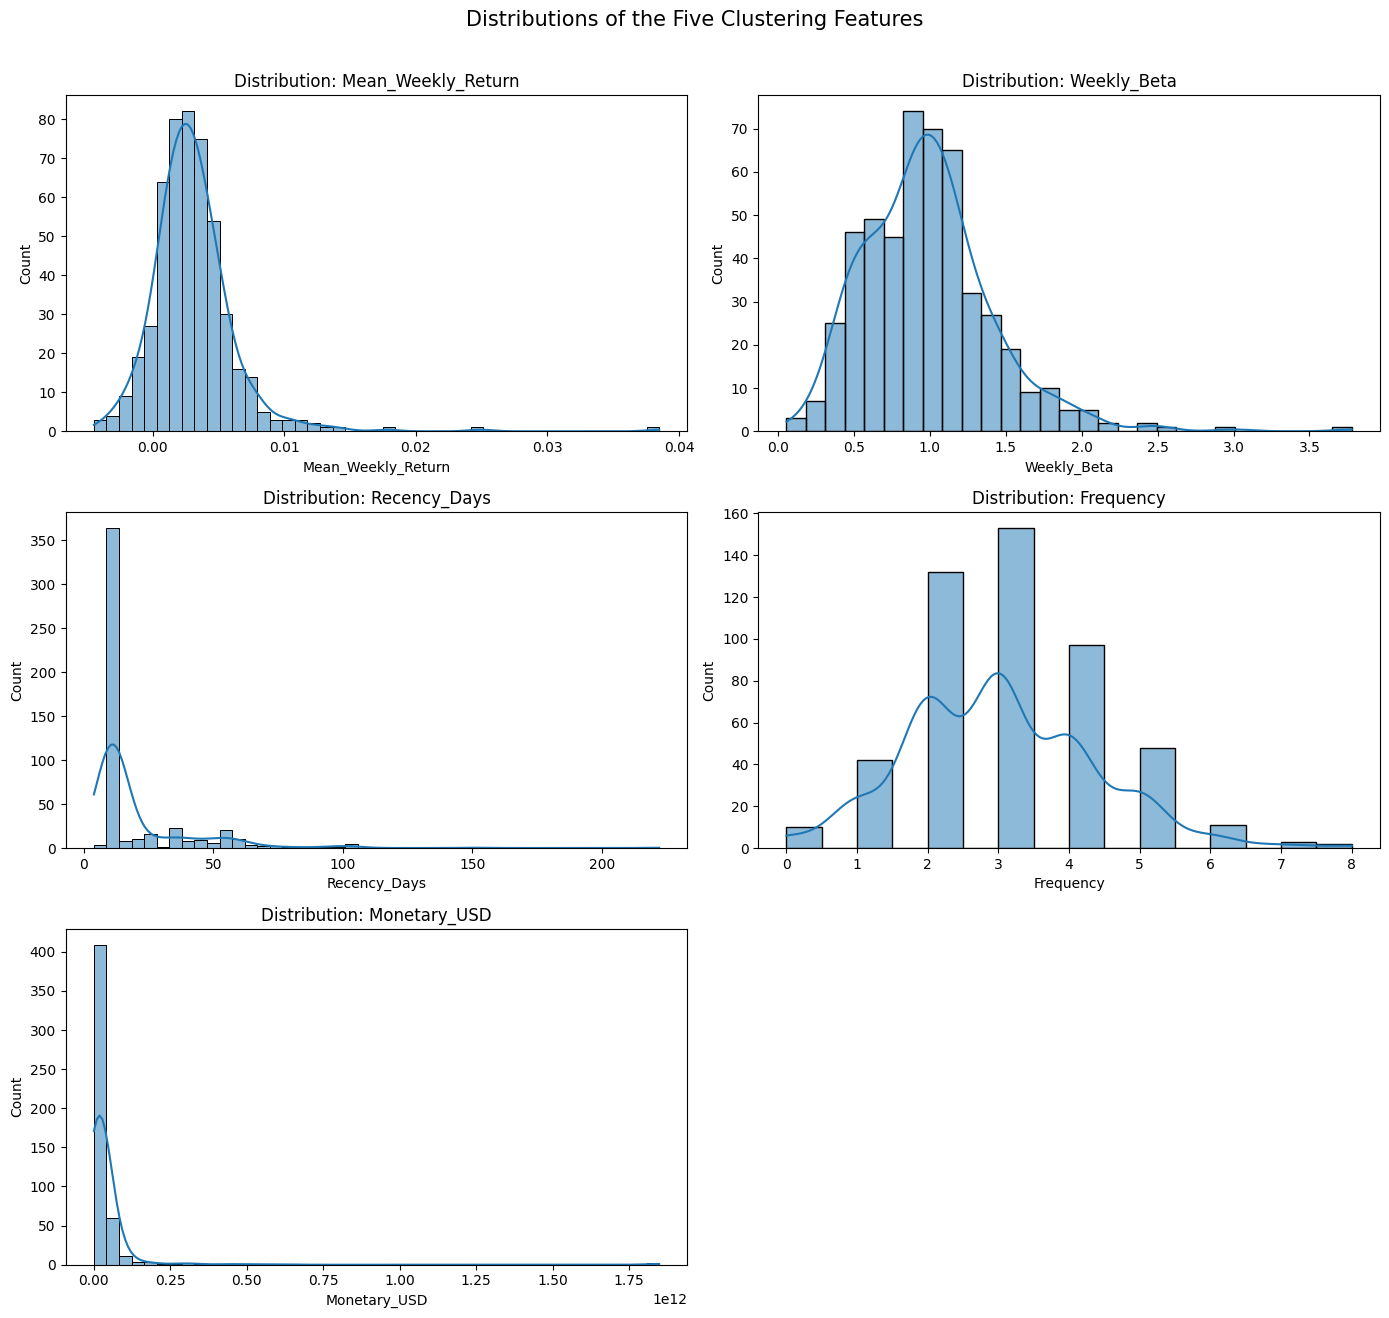

In [ ]:
# 6.2 Feature distribution, skew and outlier inspection
feature_summary = feature_table[required_feature_columns].describe().T
feature_summary["Skewness"] = feature_table[required_feature_columns].skew()
feature_summary["IQR"] = (
    feature_table[required_feature_columns].quantile(0.75)
    - feature_table[required_feature_columns].quantile(0.25)
)
feature_summary.to_csv(os.path.join(OUTPUT_DIR, "feature_summary.csv"))

print("Feature summary:")
display(feature_summary)

# Five features: use a 3x2 layout and remove the unused sixth axis.
fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for ax, col in zip(axes.flat, required_feature_columns):
    sns.histplot(feature_table[col], kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

# Hide the unused sixth panel so no empty chart appears.
for ax in axes.flat[len(required_feature_columns):]:
    fig.delaxes(ax)

fig.suptitle("Distributions of the Five Clustering Features", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "feature_distributions.png"),
    dpi=250,
    bbox_inches="tight"
)
plt.show()


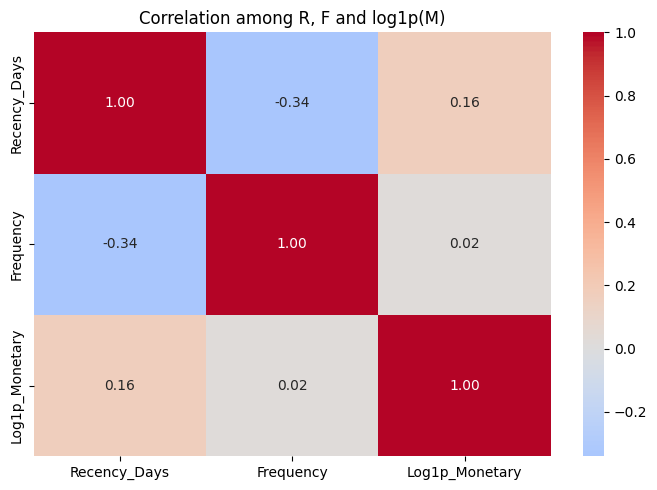

,Recency_Days,Frequency,Log1p_Monetary
Recency_Days,1.000000,-0.340235,0.164673
Frequency,-0.340235,1.000000,0.021868
Log1p_Monetary,0.164673,0.021868,1.000000


In [ ]:
# 6.3 Correlation analysis among R, F and log1p(M)
rfm_for_correlation = rfm_features_common.copy()
rfm_for_correlation["Log1p_Monetary"] = np.log1p(rfm_for_correlation["Monetary_USD"])

rfm_correlation = rfm_for_correlation[
    ["Recency_Days", "Frequency", "Log1p_Monetary"]
].corr()

rfm_correlation.to_csv(os.path.join(OUTPUT_DIR, "rfm_correlation_matrix.csv"))

plt.figure(figsize=(7, 5))
sns.heatmap(rfm_correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation among R, F and log1p(M)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "rfm_correlation_heatmap.png"), dpi=200, bbox_inches="tight")
plt.show()

display(rfm_correlation)

In [ ]:
# 7.1 Transform monetary and standardise each matrix separately
risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()

risk_scaled = risk_scaler.fit_transform(risk_features)
risk_scaled_df = pd.DataFrame(
    risk_scaled, index=risk_features.index, columns=risk_features.columns
)

rfm_model_features = rfm_features_common.copy()
rfm_model_features["Log1p_Monetary"] = np.log1p(rfm_model_features["Monetary_USD"])
rfm_model_features = rfm_model_features[
    ["Recency_Days", "Frequency", "Log1p_Monetary"]
]

rfm_scaled = rfm_scaler.fit_transform(rfm_model_features)
rfm_scaled_df = pd.DataFrame(
    rfm_scaled, index=rfm_model_features.index, columns=rfm_model_features.columns
)

print("Risk/return scaled shape:", risk_scaled_df.shape)
print("RFM scaled shape:", rfm_scaled_df.shape)
display(risk_scaled_df.head())
display(rfm_scaled_df.head())

Risk/return scaled shape: (498, 2)
RFM scaled shape: (498, 3)


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
MMM,-0.573259,-0.269701
AOS,-0.316314,0.137430
ABT,-0.625100,-0.938868
ABBV,0.216390,-1.309562
ACN,-0.199467,0.372946


,Recency_Days,Frequency,Log1p_Monetary
Ticker,,,
MMM,-0.448029,0.750960,0.307202
AOS,-0.448029,-0.757016,-1.488869
ABT,-0.448029,-1.511005,0.628558
ABBV,-0.448029,-0.003028,1.329130
ACN,-0.448029,-0.757016,1.039821


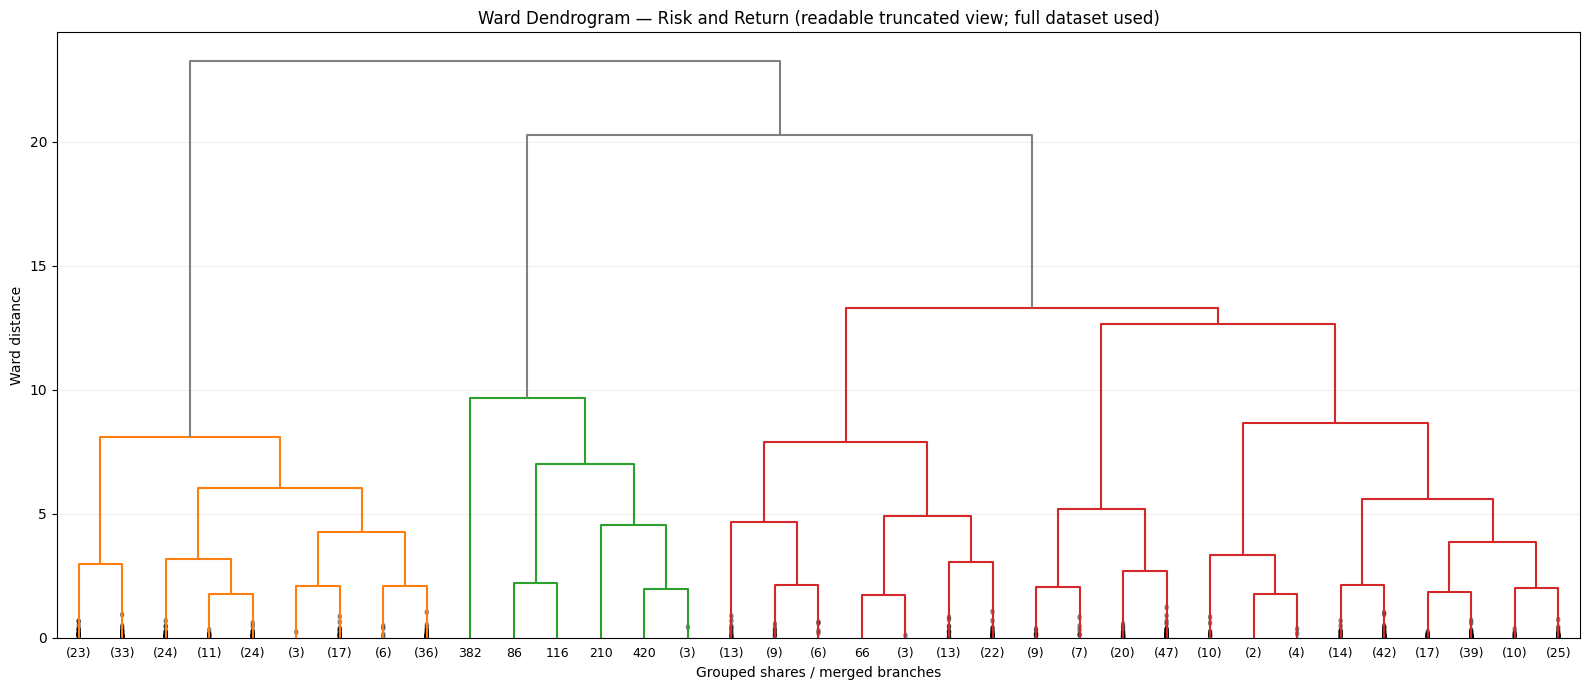

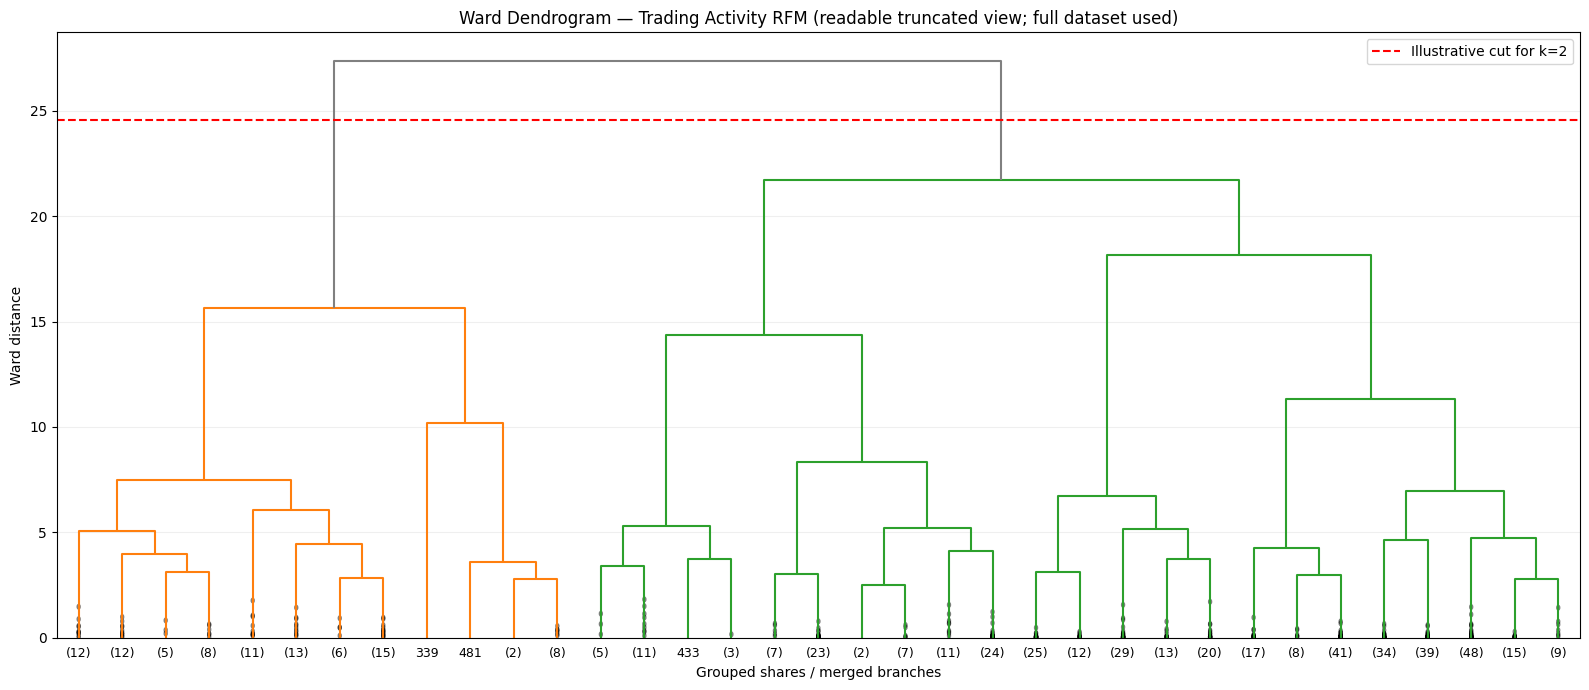

Selected Ward k — Risk/Return: 3
Selected Ward k — RFM: 2


,Feature_Set,k,Silhouette,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.288845,"{0: 321, 1: 177}",177,321
1,Risk and Return,3,0.320715,"{0: 313, 1: 177, 2: 8}",8,313
2,Risk and Return,4,0.297311,"{0: 246, 1: 177, 2: 8, 3: 67}",8,246
3,Risk and Return,5,0.288463,"{0: 8, 1: 177, 2: 163, 3: 67, 4: 83}",8,177
4,Risk and Return,6,0.289506,"{0: 163, 1: 177, 2: 7, 3: 67, 4: 83, 5: 1}",1,177
5,Risk and Return,7,0.296698,"{0: 177, 1: 67, 2: 7, 3: 147, 4: 83, 5: 1, 6: 16}",1,177
6,Risk and Return,8,0.279156,"{0: 67, 1: 121, 2: 7, 3: 147, 4: 83, 5: 1, 6: ...",1,147
7,Trading Activity RFM,2,0.358679,"{0: 404, 1: 94}",94,404
8,Trading Activity RFM,3,0.316000,"{0: 310, 1: 94, 2: 94}",94,310
9,Trading Activity RFM,4,0.287608,"{0: 94, 1: 211, 2: 94, 3: 99}",94,211


In [ ]:
# 8.1 Helper: evaluate Ward agglomerative solutions and draw readable dendrograms
def evaluate_agglomerative(X, feature_name, index):
    # Fit the full hierarchical model using every share.
    Z = linkage(X, method="ward", metric="euclidean")

    # Calculate evaluation results first so the selected number of clusters is known.
    results = []
    labels_by_k = {}

    for k in K_VALUES:
        if k >= len(index):
            continue

        model = AgglomerativeClustering(n_clusters=k, linkage="ward")
        labels = model.fit_predict(X)
        score = silhouette_score(X, labels)

        labels_by_k[k] = labels
        counts = pd.Series(labels).value_counts().sort_index().to_dict()

        results.append({
            "Feature_Set": feature_name,
            "k": k,
            "Silhouette": score,
            "Cluster_Sizes": str(counts),
            "Smallest_Cluster": min(counts.values()),
            "Largest_Cluster": max(counts.values())
        })

    results_df = pd.DataFrame(results)
    if results_df.empty:
        raise ValueError(f"No feasible cluster counts for {feature_name}.")

    selected_k = int(results_df.sort_values(
        ["Silhouette", "Smallest_Cluster"], ascending=[False, False]
    ).iloc[0]["k"])

    # For the selected k=2 solution, place the cut just below the final merge.
    # This is a visual guide only; the underlying linkage and labels are unchanged.
    if selected_k == 2 and len(Z) >= 2:
        cut_height = float((Z[-1, 2] + Z[-2, 2]) / 2)
    else:
        cut_height = None

    fig, ax = plt.subplots(figsize=(16, 7))
    dendrogram(
        Z,
        truncate_mode="lastp",
        p=35,
        show_contracted=True,
        leaf_rotation=0,
        leaf_font_size=9,
        color_threshold=cut_height,
        above_threshold_color="grey",
        ax=ax
    )

    if cut_height is not None:
        ax.axhline(
            y=cut_height,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=f"Illustrative cut for k={selected_k}"
        )
        ax.legend(loc="upper right")

    ax.set_title(
        f"Ward Dendrogram — {feature_name} (readable truncated view; full dataset used)"
    )
    ax.set_xlabel("Grouped shares / merged branches")
    ax.set_ylabel("Ward distance")
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()

    filename = (
        f"dendrogram_{feature_name.lower().replace('/', '_').replace(' ', '_')}.png"
    )
    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=250,
        bbox_inches="tight"
    )
    plt.show()

    return Z, results_df, labels_by_k, selected_k


risk_ward_linkage, risk_ward_scores, risk_ward_labels, risk_selected_k = evaluate_agglomerative(
    risk_scaled, "Risk and Return", risk_features.index
)

rfm_ward_linkage, rfm_ward_scores, rfm_ward_labels, rfm_selected_k = evaluate_agglomerative(
    rfm_scaled, "Trading Activity RFM", rfm_features_common.index
)

ward_evaluation = pd.concat([risk_ward_scores, rfm_ward_scores], ignore_index=True)
ward_evaluation.to_csv(os.path.join(OUTPUT_DIR, "agglomerative_k_evaluation.csv"), index=False)

print("Selected Ward k — Risk/Return:", risk_selected_k)
print("Selected Ward k — RFM:", rfm_selected_k)
display(ward_evaluation)


In [ ]:
# 9.1 Helper: evaluate K-Means solutions
def evaluate_kmeans(X, feature_name, index):
    results = []
    labels_by_k = {}
    models_by_k = {}

    for k in K_VALUES:
        if k >= len(index):
            continue

        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=KMEANS_N_INIT
        )
        labels = model.fit_predict(X)
        score = silhouette_score(X, labels)
        counts = pd.Series(labels).value_counts().sort_index().to_dict()

        labels_by_k[k] = labels
        models_by_k[k] = model

        results.append({
            "Feature_Set": feature_name,
            "k": k,
            "Silhouette": score,
            "Inertia": model.inertia_,
            "Cluster_Sizes": str(counts),
            "Smallest_Cluster": min(counts.values()),
            "Largest_Cluster": max(counts.values())
        })

    results_df = pd.DataFrame(results)
    if results_df.empty:
        raise ValueError(f"No feasible K-Means cluster counts for {feature_name}.")

    selected_k = int(results_df.sort_values(
        ["Silhouette", "Smallest_Cluster"], ascending=[False, False]
    ).iloc[0]["k"])

    return results_df, labels_by_k, models_by_k, selected_k


risk_kmeans_scores, risk_kmeans_labels, risk_kmeans_models, risk_kmeans_selected_k = evaluate_kmeans(
    risk_scaled, "Risk and Return", risk_features.index
)

rfm_kmeans_scores, rfm_kmeans_labels, rfm_kmeans_models, rfm_kmeans_selected_k = evaluate_kmeans(
    rfm_scaled, "Trading Activity RFM", rfm_features_common.index
)

kmeans_evaluation = pd.concat([risk_kmeans_scores, rfm_kmeans_scores], ignore_index=True)
kmeans_evaluation.to_csv(os.path.join(OUTPUT_DIR, "kmeans_k_evaluation.csv"), index=False)

print("Selected K-Means k — Risk/Return:", risk_kmeans_selected_k)
print("Selected K-Means k — RFM:", rfm_kmeans_selected_k)
display(kmeans_evaluation)

Selected K-Means k — Risk/Return: 2
Selected K-Means k — RFM: 2


,Feature_Set,k,Silhouette,Inertia,Cluster_Sizes,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.399826,659.460917,"{0: 351, 1: 147}",147,351
1,Risk and Return,3,0.349059,498.124909,"{0: 208, 1: 281, 2: 9}",9,281
2,Risk and Return,4,0.336534,386.977293,"{0: 177, 1: 121, 2: 8, 3: 192}",8,192
3,Risk and Return,5,0.347689,318.952968,"{0: 189, 1: 7, 2: 142, 3: 103, 4: 57}",7,189
4,Risk and Return,6,0.351854,265.400046,"{0: 187, 1: 103, 2: 142, 3: 57, 4: 2, 5: 7}",2,187
5,Risk and Return,7,0.336597,232.158487,"{0: 40, 1: 110, 2: 8, 3: 56, 4: 133, 5: 1, 6: ...",1,150
6,Risk and Return,8,0.328351,195.203297,"{0: 79, 1: 128, 2: 87, 3: 7, 4: 2, 5: 53, 6: 1...",2,128
7,Trading Activity RFM,2,0.418999,1094.049704,"{0: 72, 1: 426}",72,426
8,Trading Activity RFM,3,0.325170,818.241419,"{0: 277, 1: 156, 2: 65}",65,277
9,Trading Activity RFM,4,0.340464,625.212105,"{0: 61, 1: 216, 2: 97, 3: 124}",61,216


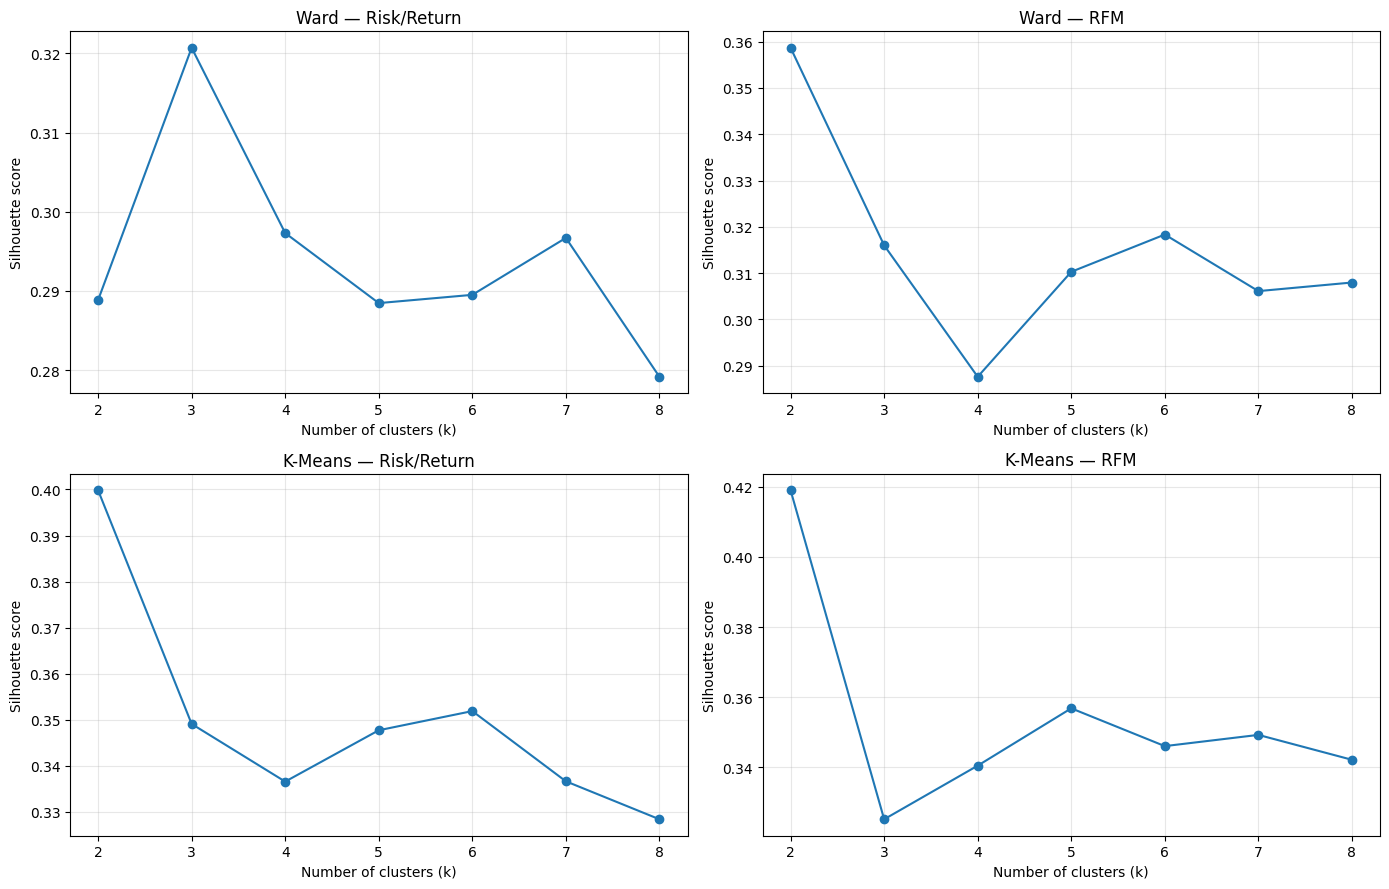

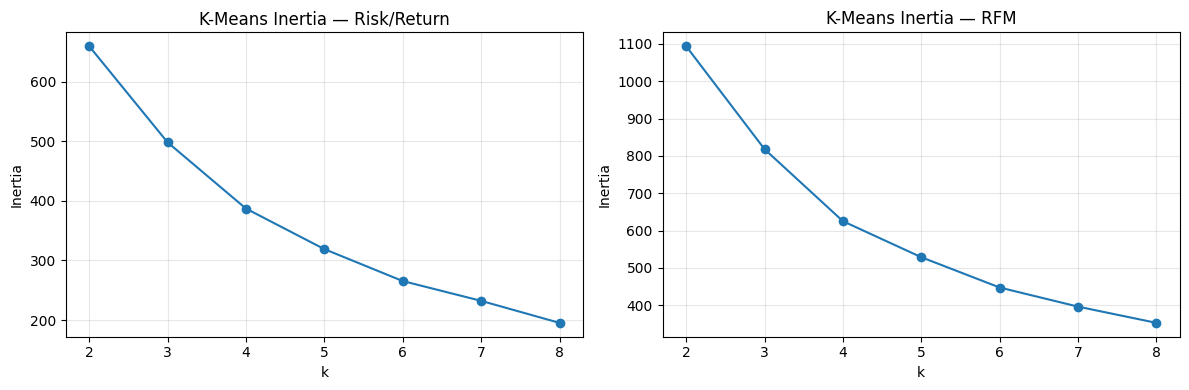

In [ ]:
# 9.2 Plot silhouette score and inertia comparisons
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, scores, title in [
    (axes[0, 0], risk_ward_scores, "Ward — Risk/Return"),
    (axes[0, 1], rfm_ward_scores, "Ward — RFM"),
    (axes[1, 0], risk_kmeans_scores, "K-Means — Risk/Return"),
    (axes[1, 1], rfm_kmeans_scores, "K-Means — RFM")
]:
    ax.plot(scores["k"], scores["Silhouette"], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Silhouette score")
    ax.set_xticks(list(K_VALUES))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "silhouette_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(risk_kmeans_scores["k"], risk_kmeans_scores["Inertia"], marker="o")
axes[0].set_title("K-Means Inertia — Risk/Return")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(rfm_kmeans_scores["k"], rfm_kmeans_scores["Inertia"], marker="o")
axes[1].set_title("K-Means Inertia — RFM")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Inertia")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "kmeans_inertia.png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# 10.1 Fit final four baseline solutions using selected k values
final_labels = pd.DataFrame(index=feature_table.index)

final_labels["Ward_Risk_Return"] = AgglomerativeClustering(
    n_clusters=risk_selected_k, linkage="ward"
).fit_predict(risk_scaled)

final_labels["KMeans_Risk_Return"] = KMeans(
    n_clusters=risk_kmeans_selected_k,
    random_state=RANDOM_STATE,
    n_init=KMEANS_N_INIT
).fit_predict(risk_scaled)

final_labels["Ward_RFM"] = AgglomerativeClustering(
    n_clusters=rfm_selected_k, linkage="ward"
).fit_predict(rfm_scaled)

final_labels["KMeans_RFM"] = KMeans(
    n_clusters=rfm_kmeans_selected_k,
    random_state=RANDOM_STATE,
    n_init=KMEANS_N_INIT
).fit_predict(rfm_scaled)

final_results = feature_table.join(final_labels)
final_results.to_csv(os.path.join(OUTPUT_DIR, "share_features_and_four_cluster_assignments.csv"))

print("Final cluster sizes:")
for column in final_labels.columns:
    print("\n", column)
    display(final_labels[column].value_counts().sort_index().rename("Shares").to_frame())

Final cluster sizes:

 Ward_Risk_Return


,Shares
Ward_Risk_Return,
0,313
1,177
2,8



 KMeans_Risk_Return


,Shares
KMeans_Risk_Return,
0,351
1,147



 Ward_RFM


,Shares
Ward_RFM,
0,404
1,94



 KMeans_RFM


,Shares
KMeans_RFM,
0,72
1,426


In [ ]:
# 10.2 Cluster profiles in original, interpretable units
def create_cluster_profiles(data, cluster_column, feature_columns):
    profiles = data.groupby(cluster_column)[feature_columns].agg(["count", "mean", "median", "std"])
    return profiles

risk_profile_data = feature_table[["Mean_Weekly_Return", "Weekly_Beta"]].join(final_labels)
rfm_profile_data = feature_table[["Recency_Days", "Frequency", "Monetary_USD"]].join(final_labels)

risk_ward_profiles = risk_profile_data.groupby("Ward_Risk_Return")[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].agg(["count", "mean", "median", "std"])

risk_kmeans_profiles = risk_profile_data.groupby("KMeans_Risk_Return")[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].agg(["count", "mean", "median", "std"])

rfm_ward_profiles = rfm_profile_data.groupby("Ward_RFM")[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].agg(["count", "mean", "median", "std"])

rfm_kmeans_profiles = rfm_profile_data.groupby("KMeans_RFM")[
    ["Recency_Days", "Frequency", "Monetary_USD"]
].agg(["count", "mean", "median", "std"])

risk_ward_profiles.to_csv(os.path.join(OUTPUT_DIR, "ward_risk_return_cluster_profiles.csv"))
risk_kmeans_profiles.to_csv(os.path.join(OUTPUT_DIR, "kmeans_risk_return_cluster_profiles.csv"))
rfm_ward_profiles.to_csv(os.path.join(OUTPUT_DIR, "ward_rfm_cluster_profiles.csv"))
rfm_kmeans_profiles.to_csv(os.path.join(OUTPUT_DIR, "kmeans_rfm_cluster_profiles.csv"))

print("Ward risk/return profiles:")
display(risk_ward_profiles)

print("K-Means risk/return profiles:")
display(risk_kmeans_profiles)

print("Ward RFM profiles:")
display(rfm_ward_profiles)

print("K-Means RFM profiles:")
display(rfm_kmeans_profiles)

Ward risk/return profiles:


Mean_Weekly_Return                               Weekly_Beta                              
                              count      mean    median       std       count      mean    median       std
Ward_Risk_Return                                                                                           
0                               313  0.003205  0.003025  0.002686         313  1.177963  1.100382  0.286272
1                               177  0.002084  0.001998  0.001914         177  0.578851  0.586638  0.167169
2                                 8  0.017432  0.014009  0.010030           8  2.369210  2.280412  0.756595

K-Means risk/return profiles:


Mean_Weekly_Return                               Weekly_Beta                              
                                count      mean    median       std       count      mean    median       std
KMeans_Risk_Return                                                                                           
0                                 351  0.002024  0.002048  0.001926         351  0.798552  0.829637  0.271265
1                                 147  0.005449  0.004801  0.004467         147  1.427354  1.350082  0.405050

Ward RFM profiles:


Recency_Days                              Frequency                            Monetary_USD                                          
                count       mean median        std     count      mean median       std        count          mean        median           std
Ward_RFM                                                                                                                                      
0                 404  12.361386   11.0   5.274885       404  3.220297    3.0  1.275259          404  3.820898e+10  1.547309e+10  1.100471e+11
1                  94  55.531915   53.0  27.639267        94  2.074468    2.0  1.138187           94  4.565006e+10  2.095020e+10  1.867560e+11

K-Means RFM profiles:


Recency_Days                              Frequency                            Monetary_USD                                          
                  count       mean median        std     count      mean median       std        count          mean        median           std
KMeans_RFM                                                                                                                                      
0                    72  62.486111   55.0  28.046236        72  1.847222    2.0  1.146455           72  8.060058e+10  2.308445e+10  3.005784e+11
1                   426  13.415493   11.0   6.898501       426  3.199531    3.0  1.255613          426  3.268613e+10  1.556962e+10  6.082316e+10

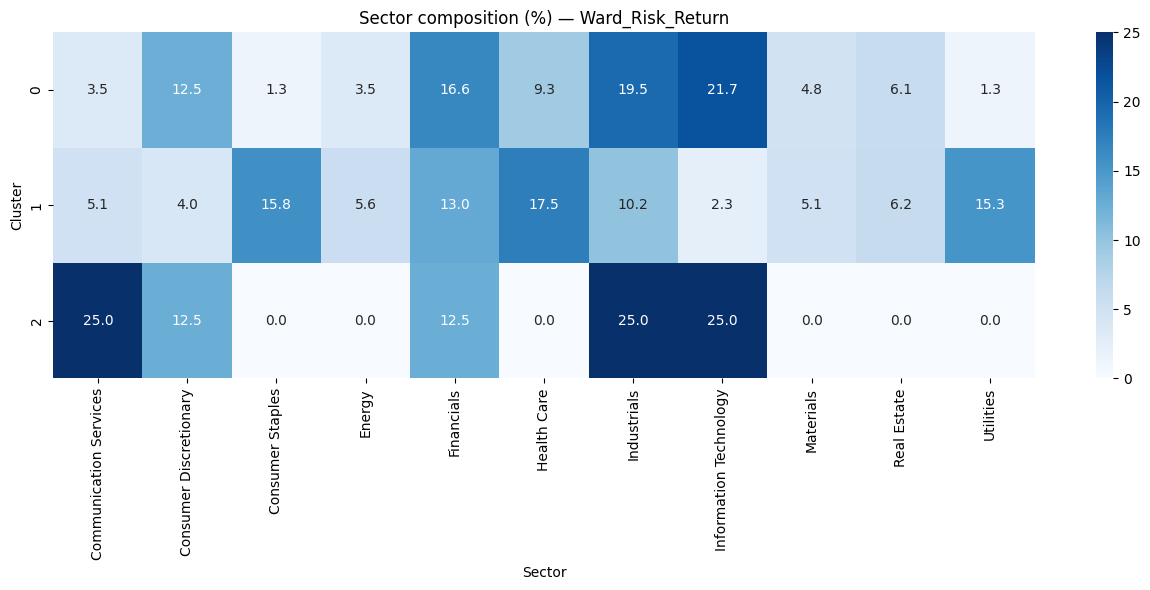

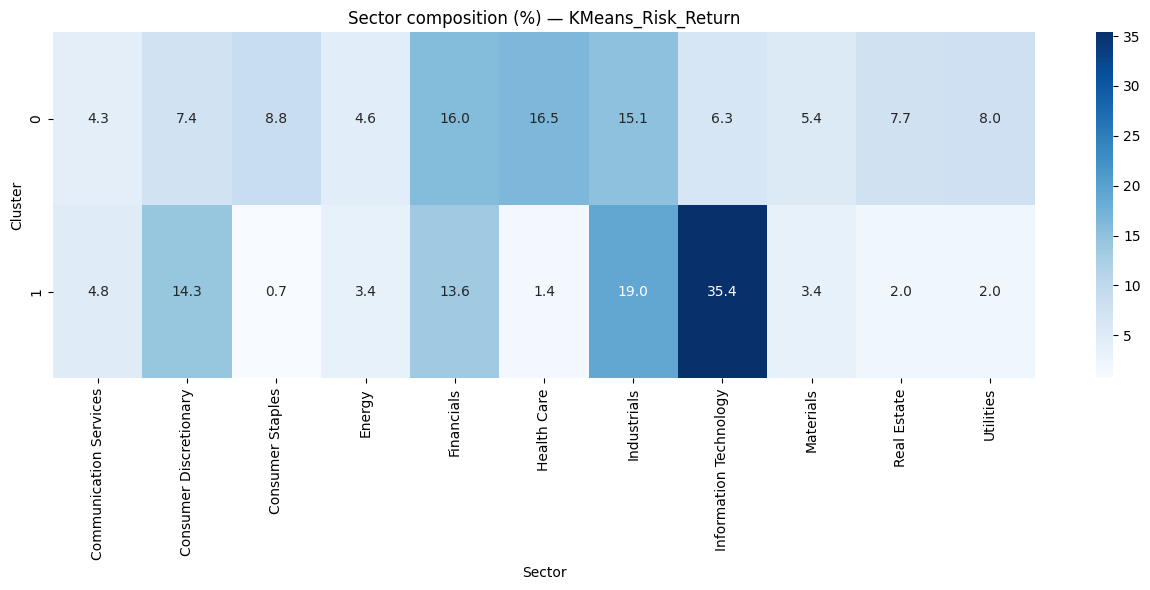

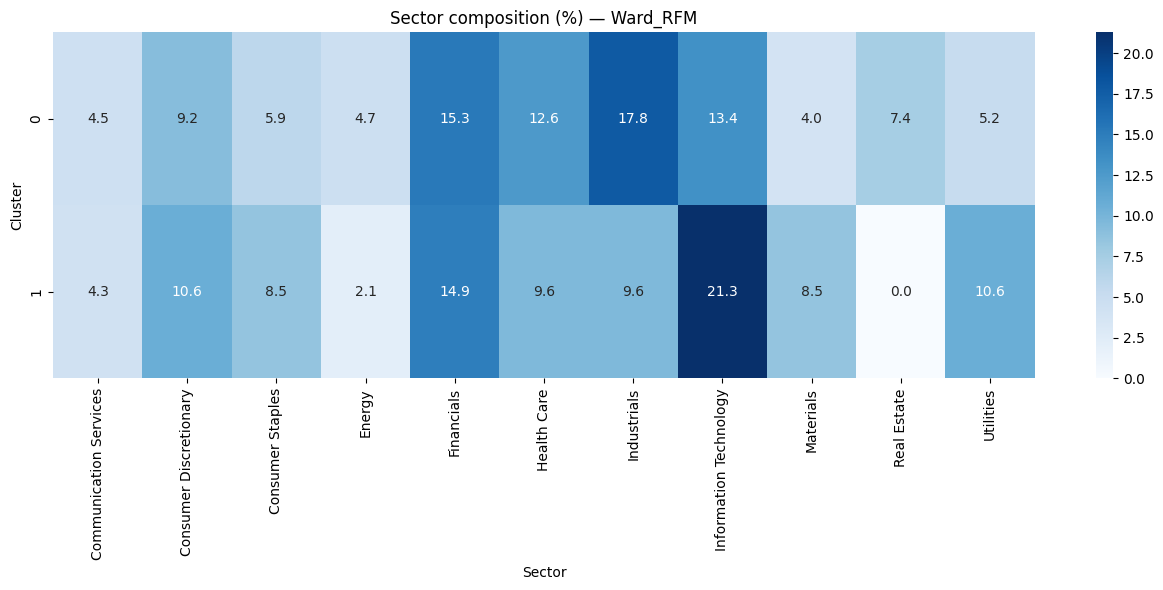

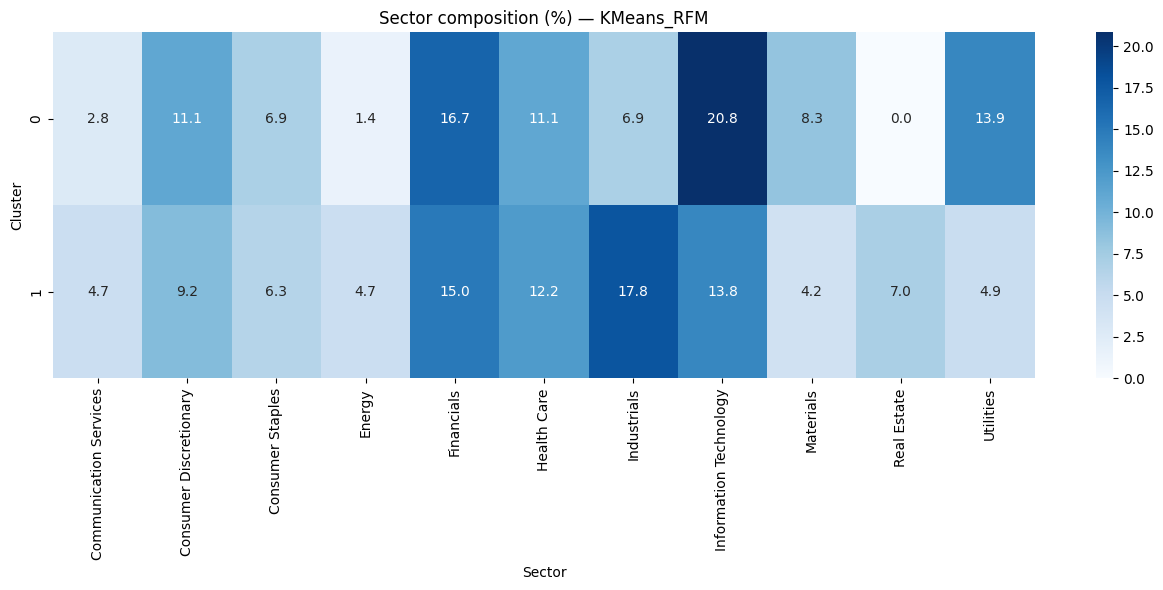

In [ ]:
# 10.3 Sector composition by cluster
sector_cluster_tables = {}

for cluster_col in final_labels.columns:
    table = pd.crosstab(
        final_results[cluster_col],
        final_results["Sector"],
        normalize="index"
    ) * 100
    sector_cluster_tables[cluster_col] = table
    table.to_csv(os.path.join(OUTPUT_DIR, f"sector_composition_{cluster_col}.csv"))

    plt.figure(figsize=(13, 6))
    sns.heatmap(table, annot=True, fmt=".1f", cmap="Blues")
    plt.title(f"Sector composition (%) — {cluster_col}")
    plt.xlabel("Sector")
    plt.ylabel("Cluster")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"sector_heatmap_{cluster_col}.png"), dpi=200, bbox_inches="tight")
    plt.show()

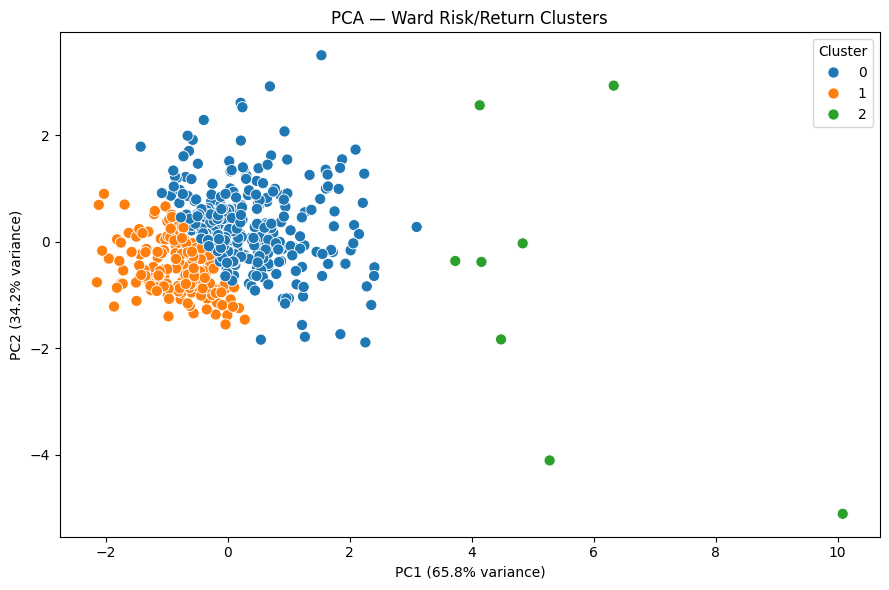

PCA — Ward Risk/Return Clusters | Total variance explained by first two PCs: 100.0 %


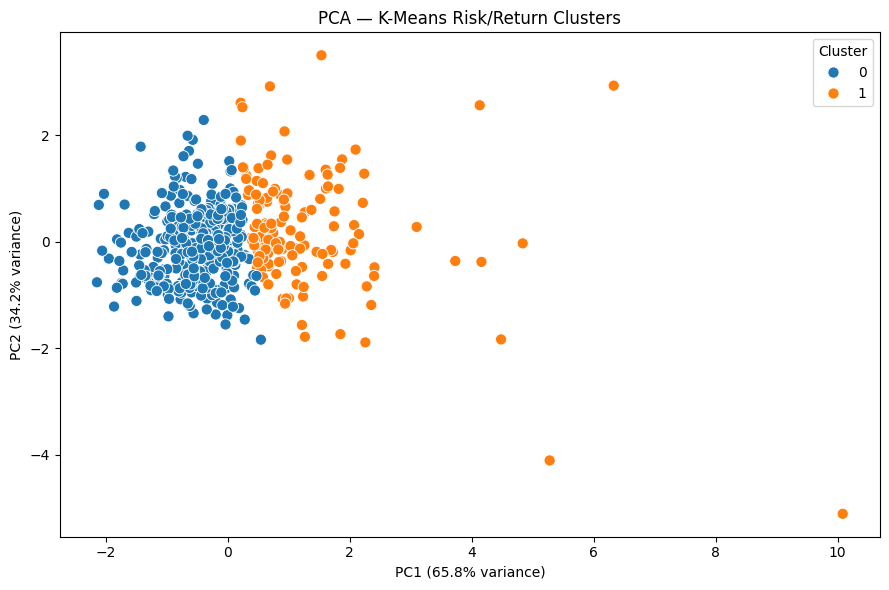

PCA — K-Means Risk/Return Clusters | Total variance explained by first two PCs: 100.0 %


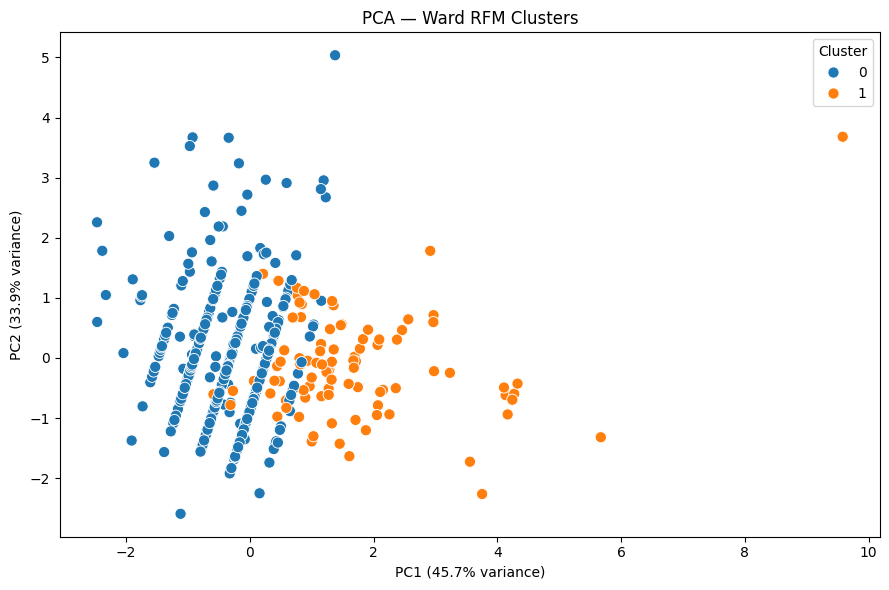

PCA — Ward RFM Clusters | Total variance explained by first two PCs: 79.56 %


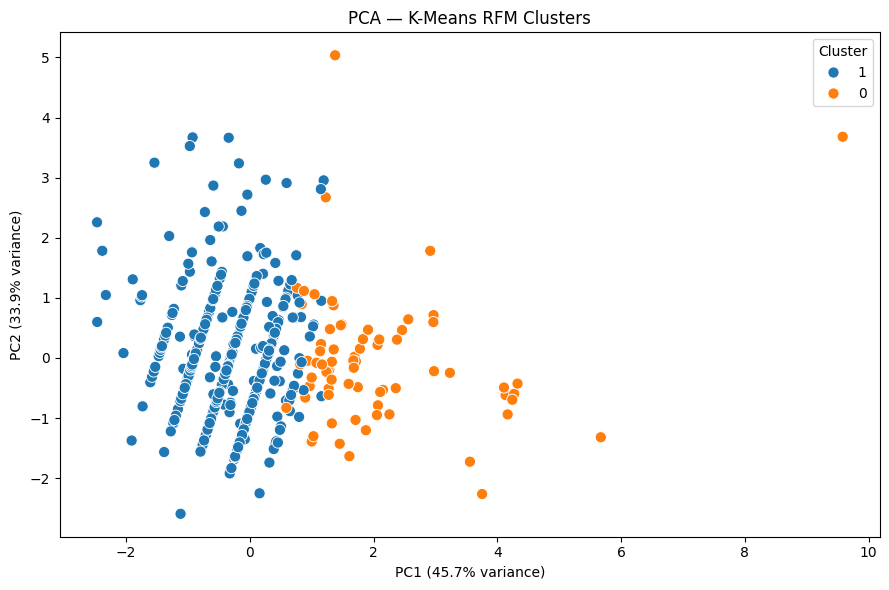

PCA — K-Means RFM Clusters | Total variance explained by first two PCs: 79.56 %


In [ ]:
# 11.1 PCA visualisation for each feature set and algorithm
def plot_pca_clusters(X_scaled, labels, title, filename):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    coordinates = pca.fit_transform(X_scaled)

    plot_data = pd.DataFrame({
        "PC1": coordinates[:, 0],
        "PC2": coordinates[:, 1],
        "Cluster": labels.astype(str)
    })

    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=65)
    plt.title(title)
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
    plt.legend(title="Cluster")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200, bbox_inches="tight")
    plt.show()

    print(title, "| Total variance explained by first two PCs:",
          round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


plot_pca_clusters(
    risk_scaled, final_labels["Ward_Risk_Return"].values,
    "PCA — Ward Risk/Return Clusters", "pca_ward_risk_return.png"
)
plot_pca_clusters(
    risk_scaled, final_labels["KMeans_Risk_Return"].values,
    "PCA — K-Means Risk/Return Clusters", "pca_kmeans_risk_return.png"
)
plot_pca_clusters(
    rfm_scaled, final_labels["Ward_RFM"].values,
    "PCA — Ward RFM Clusters", "pca_ward_rfm.png"
)
plot_pca_clusters(
    rfm_scaled, final_labels["KMeans_RFM"].values,
    "PCA — K-Means RFM Clusters", "pca_kmeans_rfm.png"
)

In [ ]:
# 12.1 Compare Ward and K-Means memberships
risk_ari = adjusted_rand_score(
    final_labels["Ward_Risk_Return"],
    final_labels["KMeans_Risk_Return"]
)
rfm_ari = adjusted_rand_score(
    final_labels["Ward_RFM"],
    final_labels["KMeans_RFM"]
)

algorithm_comparison = pd.DataFrame({
    "Feature_Set": ["Risk and Return", "Trading Activity RFM"],
    "Ward_Selected_k": [risk_selected_k, rfm_selected_k],
    "KMeans_Selected_k": [risk_kmeans_selected_k, rfm_kmeans_selected_k],
    "Adjusted_Rand_Index": [risk_ari, rfm_ari]
})

algorithm_comparison.to_csv(os.path.join(OUTPUT_DIR, "algorithm_comparison_ari.csv"), index=False)
display(algorithm_comparison)

,Feature_Set,Ward_Selected_k,KMeans_Selected_k,Adjusted_Rand_Index
0,Risk and Return,3,2,0.087157
1,Trading Activity RFM,2,2,0.753690


In [ ]:
# 13.1 Refit Ward RFM using Recency and Frequency only
rf_features_only = rfm_features_common[["Recency_Days", "Frequency"]].copy()
rf_scaler = StandardScaler()
rf_scaled = rf_scaler.fit_transform(rf_features_only)

ward_rf_only_model = AgglomerativeClustering(
    n_clusters=rfm_selected_k,
    linkage="ward"
)
ward_rf_only_labels = ward_rf_only_model.fit_predict(rf_scaled)

monetary_removal_ari = adjusted_rand_score(
    final_labels["Ward_RFM"],
    ward_rf_only_labels
)

final_labels["Ward_RF_Only"] = ward_rf_only_labels
final_results["Ward_RF_Only"] = ward_rf_only_labels

print("ARI: Full Ward RFM vs Ward R/F-only:", round(monetary_removal_ari, 4))
print("R/F-only cluster sizes:")
display(pd.Series(ward_rf_only_labels).value_counts().sort_index().rename("Shares").to_frame())

ARI: Full Ward RFM vs Ward R/F-only: 0.9531
R/F-only cluster sizes:


,Shares
0,405
1,93


In [ ]:
# 13.2 Compare traded value profiles after Monetary removal
rf_only_traded_value_profile = final_results.groupby("Ward_RF_Only")["Monetary_USD"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)
full_rfm_traded_value_profile = final_results.groupby("Ward_RFM")["Monetary_USD"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

rf_only_traded_value_profile.to_csv(
    os.path.join(OUTPUT_DIR, "rf_only_cluster_traded_value_profiles.csv")
)
full_rfm_traded_value_profile.to_csv(
    os.path.join(OUTPUT_DIR, "full_rfm_cluster_traded_value_profiles.csv")
)

print("Traded value by full RFM Ward clusters:")
display(full_rfm_traded_value_profile)
print("Traded value by R/F-only Ward clusters:")
display(rf_only_traded_value_profile)

Traded value by full RFM Ward clusters:


,count,mean,median,std,min,max
Ward_RFM,,,,,,
0,404,3.820898e+10,1.547309e+10,1.100471e+11,1.297483e+09,1.847697e+12
1,94,4.565006e+10,2.095020e+10,1.867560e+11,4.373583e+09,1.825337e+12


Traded value by R/F-only Ward clusters:


,count,mean,median,std,min,max
Ward_RF_Only,,,,,,
0,405,3.768854e+10,1.545679e+10,1.095602e+11,1.297483e+09,1.847697e+12
1,93,4.799647e+10,2.105259e+10,1.885560e+11,4.373583e+09,1.825337e+12


In [ ]:
# 14.1 Final feature table with all cluster assignments

import json
import os
from IPython.display import display

# Display the final feature table directly in the notebook
print("Final Feature Table – Share Details and Cluster Assignments")
print(f"Total shares: {len(final_results)}")

display(
    final_results
    .sort_values("Ticker")
    .reset_index(drop=True)
)

# Export the final feature table as CSV
csv_path = os.path.join(
    OUTPUT_DIR,
    "final_feature_table_with_cluster_assignments.csv"
)
final_results.to_csv(csv_path, index=False)

# Export all analysis tables to Excel
excel_path = os.path.join(
    OUTPUT_DIR,
    "coursework_analysis_tables.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    ticker_metadata.to_excel(writer, sheet_name="Ticker_List", index=False)
    validation_log.to_excel(writer, sheet_name="Validation_Log", index=False)
    risk_return_features.to_excel(writer, sheet_name="Risk_Return_Features")
    rfm_features.to_excel(writer, sheet_name="Adapted_RFM")
    feature_table.to_excel(writer, sheet_name="Common_Features")
    final_results.to_excel(writer, sheet_name="Cluster_Assignments", index=False)
    ward_evaluation.to_excel(writer, sheet_name="Ward_Evaluation", index=False)
    kmeans_evaluation.to_excel(writer, sheet_name="KMeans_Evaluation", index=False)
    algorithm_comparison.to_excel(writer, sheet_name="Algorithm_Comparison", index=False)
    rfm_correlation.to_excel(writer, sheet_name="RFM_Correlation")

# Save run metadata
run_metadata = {
    "Study_Start": START_DATE,
    "Study_End_Exclusive": END_DATE,
    "Ticker_List_Retrieval_Date_UTC": TICKER_RETRIEVAL_DATE,
    "Observation_Date": str(OBSERVATION_DATE.date()),
    "Benchmark": BENCHMARK_TICKER,
    "Weekly_Price_Field": weekly_price_field,
    "Baseline_Sessions": BASELINE_SESSIONS,
    "RFM_Window_Sessions": RFM_WINDOW_SESSIONS,
    "High_Volume_Multiplier": HIGH_VOLUME_MULTIPLIER,
    "Minimum_Paired_Weeks_For_Beta": MIN_PAIRED_WEEKS,
    "Initial_Tickers": len(tickers),
    "Initially_Valid_Tickers": len(valid_tickers),
    "Common_Shares_Clustered": len(feature_table),
    "Risk_Ward_Selected_k": risk_selected_k,
    "Risk_KMeans_Selected_k": risk_kmeans_selected_k,
    "RFM_Ward_Selected_k": rfm_selected_k,
    "RFM_KMeans_Selected_k": rfm_kmeans_selected_k,
    "Ward_RFM_vs_RF_Only_ARI": monetary_removal_ari,
    "Package_Versions": PACKAGE_VERSIONS
}

with open(os.path.join(OUTPUT_DIR, "run_metadata.json"), "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, indent=2, default=str)

print("\nAnalysis complete.")
print("CSV file:", csv_path)
print("Excel workbook:", excel_path)
print("Metadata saved successfully.")

Final Feature Table – Share Details and Cluster Assignments
Total shares: 498


,Mean_Weekly_Return,Weekly_Beta,Paired_Weekly_Observations,Beta_History_Flag,Observation_Date,Latest_High_Volume_Date,Recency_Days,Frequency,Monetary_USD,RFM_Window_Start,RFM_Window_End,RFM_Window_Sessions,Sector,Ward_Risk_Return,KMeans_Risk_Return,Ward_RFM,KMeans_RFM,Ward_RF_Only
0,0.001121,1.074724,207,Sufficient history,2024-12-31,2024-12-20,11,2,1.400180e+10,2024-10-07,2024-12-31,60,Health Care,0,0,0,1,0
1,0.003930,1.174836,207,Sufficient history,2024-12-31,2024-12-20,11,2,6.233034e+11,2024-10-07,2024-12-31,60,Information Technology,0,1,0,1,0
2,0.003749,0.425366,207,Sufficient history,2024-12-31,2024-12-20,11,3,6.837054e+10,2024-10-07,2024-12-31,60,Health Care,1,0,0,1,0
3,0.001475,1.472709,207,Sufficient history,2024-12-31,2024-12-20,11,3,3.652850e+10,2024-10-07,2024-12-31,60,Consumer Discretionary,0,1,0,1,0
4,0.000971,0.583543,207,Sufficient history,2024-12-31,2024-12-20,11,1,3.523027e+10,2024-10-07,2024-12-31,60,Health Care,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
493,-0.001554,2.504520,207,Sufficient history,2024-12-31,2024-11-12,49,5,4.052406e+10,2024-10-07,2024-12-31,60,Financials,0,1,1,1,0
494,0.001807,0.631435,207,Sufficient history,2024-12-31,2024-11-05,56,1,1.339492e+10,2024-10-07,2024-12-31,60,Consumer Discretionary,1,0,1,0,1
495,-0.001105,0.798202,207,Sufficient history,2024-12-31,2024-12-20,11,2,9.609458e+09,2024-10-07,2024-12-31,60,Health Care,1,0,0,1,0
496,0.001181,1.618418,207,Sufficient history,2024-12-31,2024-12-20,11,4,8.326927e+09,2024-10-07,2024-12-31,60,Information Technology,0,1,0,1,0



Analysis complete.
CSV file: coursework_outputs_20232098/final_feature_table_with_cluster_assignments.csv
Excel workbook: coursework_outputs_20232098/coursework_analysis_tables.xlsx
Metadata saved successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
from google.colab import files
import shutil

# Compress all output files into one ZIP folder
shutil.make_archive(
    "/content/coursework_outputs_20232098",
    "zip",
    OUTPUT_DIR
)

# Download the ZIP file to your computer
files.download("/content/coursework_outputs_20232098.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>